# Phase I — Data Pipeline (KDDM Ice Hockey Scouting)

**Group 174**

| Member | Matriculation # | Role |
|--------|----------------|------|
| Muhammad Saim Akram | 12344542 | Phase I (preprocessing, cleaning, EDA) |
| Zamarak Sufyan | — | Phase II (modeling, evaluation) |

**Project brief:** `docs/PROJECT_UNDERSTANDING.md` · **Phase I deadline:** 2026-05-03

This single notebook produces the cleaned master dataset (`data/newdata/master_merged.csv`) and every figure used in the Phase I presentation. Sections map directly to the 8 required slides; section headers note which slide they feed.


## §1 — Approach (feeds slide 1)

The dataset is split across **7 files** in **5 different formats** describing the same 10,000 players. Our strategy:

1. **Load each file with the correct reader**, recording shape and null counts without altering data.
2. **Clean each source in isolation** — typos, mixed units, Latin/Roman encoding, inconsistent casing — before merging.
3. **Build a single 10,000-row master** by left-joining onto a unified identity table (`identity_card_0` + `identity_card_1`).
4. **Investigate** the systematic 37-row missing pattern instead of silently dropping it.
5. **Impute** numeric features by *position* (better than a global median when role distributions differ).
6. **Save** the cleaned master to `data/newdata/master_merged.csv` and every figure to `docs/figures/`.

Tools: `pandas`, `numpy`, `matplotlib`, `openpyxl`. No external services. Restart-and-run-all reproducible.


In [1]:
from __future__ import annotations

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT  = DATA / "newdata"
FIGS = ROOT / "docs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})

# Team palette
C_NAVY, C_RED, C_GREEN, C_GOLD, C_PURPLE = (
    "#0B2E4F", "#C8102E", "#2E8B57", "#DAA520", "#6A0DAD",
)


## §2 — Loading the 7 files (feeds slide 2)

Each file format needs a different reader. We load all 7 and record `shape` + null counts. **No data is dropped or modified here.**


In [2]:
contracts = pd.read_pickle(DATA / "contracts_competition.pkl")
scouting  = pd.read_csv   (DATA / "hockey_scouting_notes.csv")
id0_raw   = pd.read_csv   (DATA / "identity_card_0.tsv", sep="\t")
id1_raw   = pd.read_csv   (DATA / "identity_card_1.csv")
medical_raw = pd.read_excel(DATA / "medical_information.xlsx", engine="openpyxl", header=None)
moms      = pd.read_json  (DATA / "moms_notes.json")
perf      = pd.read_csv   (DATA / "performance.tsv", sep="\t")

raw_frames = {
    "performance.tsv":          perf,
    "contracts_competition.pkl": contracts,
    "hockey_scouting_notes.csv": scouting,
    "identity_card_1.csv":       id1_raw,
    "identity_card_0.tsv":       id0_raw,
    "medical_information.xlsx":  medical_raw,
    "moms_notes.json":           moms,
}
summary = pd.DataFrame({
    "rows":    {n: df.shape[0] for n, df in raw_frames.items()},
    "cols":    {n: df.shape[1] for n, df in raw_frames.items()},
    "nulls":   {n: int(df.isnull().sum().sum()) for n, df in raw_frames.items()},
    "dupes":   {n: int(df.duplicated().sum()) for n, df in raw_frames.items()},
})
summary


,rows,cols,nulls,dupes
performance.tsv,10000,29,1036,0
contracts_competition.pkl,10000,8,513,0
hockey_scouting_notes.csv,10000,7,1837,0
identity_card_1.csv,9112,8,222,0
identity_card_0.tsv,888,8,0,0
medical_information.xlsx,10003,11,9109,0
moms_notes.json,10000,13,3514,36


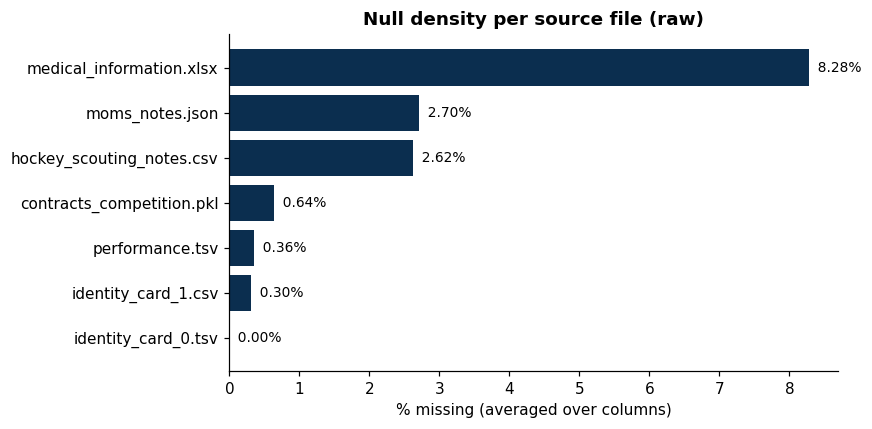

In [3]:
# Figure 1 — null-density heatmap across all 7 source files (slide 2)
fig, ax = plt.subplots(figsize=(8, 4))
density = pd.Series(
    {name: df.isnull().mean().mean() * 100 for name, df in raw_frames.items()}
).sort_values()
ax.barh(density.index, density.values, color=C_NAVY)
ax.set_xlabel("% missing (averaged over columns)")
ax.set_title("Null density per source file (raw)")
for i, v in enumerate(density.values):
    ax.text(v, i, f"  {v:.2f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGS / "fig01_null_density_per_file.png", dpi=150, bbox_inches="tight")
plt.show()


## §3 — Per-source cleaning (feeds slide 3)

Each source gets the minimum transformations needed to make it joinable and consistent. Identifiers preserved; nothing is dropped silently.


### §3.1 `identity_card_0` — Latin → English, Roman → integer

Column names are Latin, IDs are Roman numerals, last names carry Latin suffixes. We decode, rename, and strip suffixes.


In [4]:
LATIN_TO_EN = {
    "numerus_internationalis_ad_identitatem": "international_id",
    "numerus_identificationis_ad_medicinam":  "medical_id",
    "praenomen":      "first_name",
    "cognomen":       "last_name",
    "sexus":          "gender",
    "aetas_annorum":  "age",
    "urbs_natalis":   "birth_city",
    "natio":          "nationality",
}

ROMAN = {"M": 1000, "D": 500, "C": 100, "L": 50, "X": 10, "V": 5, "I": 1}

def roman_to_int(s):
    if not isinstance(s, str):
        return pd.NA
    total, prev = 0, 0
    for ch in reversed(s.upper().strip()):
        v = ROMAN.get(ch)
        if v is None:
            return pd.NA
        total += -v if v < prev else v
        prev = v
    return total

def strip_latin_suffix(name):
    if not isinstance(name, str):
        return name
    if name.endswith("ius"):
        return name[:-3]
    if name.endswith("us"):
        return name[:-2]
    return name

id0 = id0_raw.rename(columns=LATIN_TO_EN).copy()
id0["international_id"] = id0["international_id"].map(roman_to_int).astype("Int64")
id0["first_name"] = id0["first_name"].map(strip_latin_suffix)
id0["last_name"]  = id0["last_name"].map(strip_latin_suffix)

print(f"identity_card_0 shape: {id0.shape}")
id0.head()


identity_card_0 shape: (888, 8)


,international_id,medical_id,first_name,last_name,gender,age,birth_city,nationality
0,275,039e0ab7-e36d-4bc7-a0b1-3e93e8ec73e9,Keith,Allee,male,23.0,vienna,austria
1,2560,070dfb40-76c9-4894-90e5-7463d060d49b,Alyssa,Kohl,f,31.0,Vienna,austria
2,2323,fa06ed07-6f09-4ec2-9f11-a70917307270,Emily,Belanger,female,29.0,OSTRAVA,france
3,7708,59f94605-e953-4117-b9ee-09ba1392e895,Stefanie,Fiedler,female,25.0,rome,italy
4,4062,2e663575-2f96-42fc-ab59-481993a65a53,Melanie,Mulligan,female,312.0,Paris,france


### §3.2 Combined identity normalization

Both identity files have inconsistent gender / nationality casing and a few impossible ages (max ≈ 455 in raw). Normalize, then concat.


In [5]:
GENDER_MAP = {
    "m": "male", "male": "male",
    "f": "female", "female": "female",
    "other": "other",
}

def norm_gender(g):
    if not isinstance(g, str):
        return np.nan
    return GENDER_MAP.get(g.strip().lower(), g.strip().lower())

def norm_nationality(s):
    if not isinstance(s, str):
        return np.nan
    return s.strip().lower().rstrip(".")

id1 = id1_raw.copy()
for df in (id0, id1):
    df["gender"]      = df["gender"].map(norm_gender)
    df["birth_city"]  = df["birth_city"].astype("string").str.title()
    df["nationality"] = df["nationality"].map(norm_nationality)
    df.loc[df["age"] > 60, "age"] = np.nan  # impossible ages (raw max ≈ 455)

identity = (
    pd.concat([id0, id1], ignore_index=True)
      .drop_duplicates(subset=["international_id"])
      .reset_index(drop=True)
)
identity["international_id"] = identity["international_id"].astype("Int64")
print(f"combined identity: {identity.shape}  (expected 10000 rows)")
print("unique international_ids:", identity['international_id'].nunique())
print("unique medical_ids:     ", identity['medical_id'].nunique())


combined identity: (10000, 8)  (expected 10000 rows)
unique international_ids: 10000
unique medical_ids:      10000


### §3.3 `medical_information` — non-standard header + mixed units

Row 0 holds column labels, row 1 has the `medical_id` label, row 2 is metadata. Heights mix `1.79m` and `180.1135cm`, weights and body-fat mix unit suffixes, dates use three formats.


In [6]:
cols = ["medical_id"] + medical_raw.iloc[1, 1:].tolist()
medical_clean = medical_raw.iloc[3:].reset_index(drop=True).copy()
medical_clean.columns = cols

def parse_height_cm(x):
    """Return height in cm. Handles '1.79m', '180.1135cm', bare numbers."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if "nan" in s:
        return np.nan
    m = re.match(r"([\d.]+)\s*(cm|m)?", s)
    if not m:
        return np.nan
    val = float(m.group(1))
    return val * 100 if m.group(2) == "m" else val

def parse_numeric_with_suffix(x, suffix):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower().removesuffix(suffix.lower())
    try:
        return float(s)
    except ValueError:
        return np.nan

medical_clean["height"]              = medical_clean["height"].map(parse_height_cm)
medical_clean["weight"]              = medical_clean["weight"].map(lambda x: parse_numeric_with_suffix(x, "kg"))
medical_clean["body_fat_percentage"] = medical_clean["body_fat_percentage"].map(lambda x: parse_numeric_with_suffix(x, "%"))
medical_clean["age_in_years"]        = pd.to_numeric(medical_clean["age_in_years"], errors="coerce")
medical_clean["shoe_size"]           = pd.to_numeric(medical_clean["shoe_size"], errors="coerce")
medical_clean["sprint_time"]         = pd.to_numeric(medical_clean["sprint_time"], errors="coerce")
medical_clean["return_date"]         = pd.to_datetime(medical_clean["return_date"], errors="coerce")
medical_clean["fitness_level"]       = (
    medical_clean["fitness_level"].astype("string").str.lower().str.strip().replace({"nan": pd.NA})
)
# physician_signature is a joke field (Dr. House etc.) — drop here, before merging.
medical_clean = medical_clean.drop(columns=["physician_signature"])

print("medical_clean dtypes after parsing:")
print(medical_clean.dtypes)
print(f"\nheight range (cm): {medical_clean['height'].min():.1f} – {medical_clean['height'].max():.1f}")


medical_clean dtypes after parsing:
medical_id                     object
height                        float64
weight                        float64
age_in_years                  float64
shoe_size                     float64
body_fat_percentage           float64
fitness_level          string[python]
sprint_time                   float64
medical_information            object
return_date            datetime64[ns]
dtype: object

height range (cm): 131.6 – 309.0


### §3.4 `contracts_competition` — boolean fix, implausible draft years


In [7]:
contracts_clean = contracts.copy()

BOOL_MAP = {True: True, False: False, "True": True, "False": False, "true": True, "false": False}
for col in ["captain", "won_championship"]:
    contracts_clean[col] = contracts_clean[col].map(BOOL_MAP).astype("boolean")

# NHL draft began in 1963; values like 1850 are implausible.
implausible_draft = contracts_clean["draft_year"] < 1960
print(f"draft_year < 1960 set to NaN: {int(implausible_draft.sum())} rows")
contracts_clean.loc[implausible_draft, "draft_year"] = np.nan

contracts_clean.dtypes


draft_year < 1960 set to NaN: 40 rows


international_id              int64
contracts_signed            float64
salary                      float64
captain                     boolean
won_championship            boolean
jersey_number               float64
draft_year                  float64
number_of_previous_teams    float64
dtype: object

### §3.5 `performance` — rename the `penality_minutes` typo


In [8]:
perf_clean = perf.rename(columns={"penality_minutes": "penalty_minutes"}).copy()
print(f"performance shape: {perf_clean.shape}")
print(f"penalty_minutes column present: {'penalty_minutes' in perf_clean.columns}")


performance shape: (10000, 29)
penalty_minutes column present: True


### §3.6 `hockey_scouting_notes` — lowercase categoricals


In [9]:
scouting_clean = scouting.copy()
for col in ["position", "dominant_hand", "experience_level"]:
    scouting_clean[col] = scouting_clean[col].astype("string").str.lower().str.strip()

print("unique values per column:")
print(scouting_clean[["position", "dominant_hand", "experience_level"]].nunique())


unique values per column:
position            5
dominant_hand       2
experience_level    4
dtype: int64


### §3.7 `moms_notes` — drop constants, dedup


In [10]:
constant_cols = [c for c in moms.columns if moms[c].nunique(dropna=False) <= 1]
print("constant columns dropped from moms_notes:", constant_cols)

moms_clean = moms.drop(columns=constant_cols).drop_duplicates().reset_index(drop=True)
moms_clean.loc[moms_clean["age"] > 60, "age"] = np.nan
print(f"moms_clean shape: {moms_clean.shape}")


constant columns dropped from moms_notes: ['favourite_child_info', 'favourite_tv_show', 'favourite_food']
moms_clean shape: (9964, 10)


## §4 — Build the master table (still slide 3)

Left-joins keep all 10,000 identity rows. `moms_notes` has no ID, so we build a `name_key` from `first_name` + `last_name` (after stripping Latin suffixes in §3.1, which makes the names match).


In [11]:
master = (
    identity
    .merge(perf_clean,       on="international_id", how="left")
    .merge(contracts_clean,  on="international_id", how="left")
    .merge(scouting_clean,   on="international_id", how="left")
    .merge(medical_clean,    on="medical_id",       how="left")
)
print(f"after ID-based joins: {master.shape}")


after ID-based joins: (10000, 58)


In [12]:
def name_key(df):
    return (
        df["first_name"].astype("string").str.lower().str.strip() + "_" +
        df["last_name"].astype("string").str.lower().str.strip()
    )

master["name_key"]    = name_key(master)
moms_clean["name_key"] = name_key(moms_clean)

matched = set(master["name_key"]) & set(moms_clean["name_key"])
print(f"name_key matches: {len(matched)}  (of {master['name_key'].nunique()} master keys)")

master = master.merge(
    moms_clean.drop_duplicates(subset="name_key", keep="first"),
    on="name_key", how="left", suffixes=("", "_moms"),
)
master = master.drop(columns=[c for c in master.columns if c.endswith("_moms") or c == "name_key"])
master = master.drop_duplicates(subset="international_id", keep="first").reset_index(drop=True)
print(f"after moms_notes join: {master.shape}  (expected 10000 rows)")


name_key matches: 9815  (of 9818 master keys)


after moms_notes join: (10000, 64)  (expected 10000 rows)

In [13]:
# Drop the obvious distractor / 100%-empty columns now that the merge is done.
DROP_DISTRACTORS = [
    "eye_color",
    "stuffed_animal_name",
    "favourite_board_game",
    "favourite_child_info",
    "favourite_tv_show",
    "favourite_food",
]
master = master.drop(columns=[c for c in DROP_DISTRACTORS if c in master.columns])
print(f"after distractor drop: {master.shape}")
print(f"columns: {list(master.columns)}")


after distractor drop: (10000, 61)
columns: ['international_id', 'medical_id', 'first_name', 'last_name', 'gender', 'age', 'birth_city', 'nationality', 'goals', 'assists', 'num_of_shots', 'shot_speed', 'shot_attempts', 'shooting_percentage', 'high_danger_shots', 'medium_danger_shots', 'low_danger_shots', 'save_percentage', 'winning_goals', 'power_play_time', 'power_play_goals', 'time_on_ice', 'faceoff_win_percentage', 'puck_touches', 'puck_recoveries', 'puck_possession_time', 'penalty_kill_time', 'penalty_minutes', 'penalties_taken', 'time_between_penalties', 'goals_against_total', 'goals_against_average', 'passes_attempted', 'passes_completed', 'pass_completion_rate', 'games_missed_due_to_injury', 'contracts_signed', 'salary', 'captain', 'won_championship', 'jersey_number', 'draft_year', 'number_of_previous_teams', 'position', 'dominant_hand', 'experience_level', 'years_played', 'years_pro', 'scout_notes', 'height', 'weight', 'age_in_years', 'shoe_size', 'body_fat_percentage', 'fitnes

## §5 — Distributions (feeds slide 4)

Four panels: position counts, age (after outlier removal), salary on a log scale, height in cm.


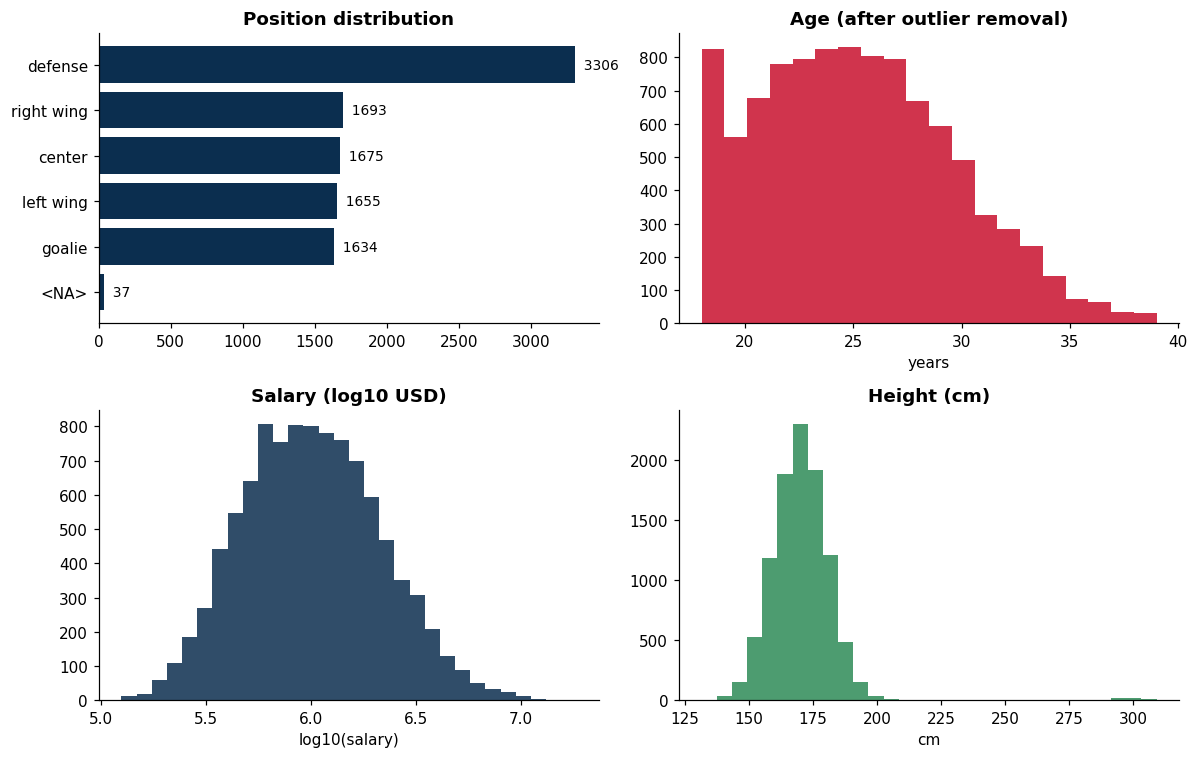

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

ax = axes[0, 0]
pos = master["position"].value_counts(dropna=False)
ax.barh(pos.index.astype(str), pos.values, color=C_NAVY)
ax.invert_yaxis()
ax.set_title("Position distribution")
for i, v in enumerate(pos.values):
    ax.text(v, i, f"  {v}", va="center", fontsize=9)

ax = axes[0, 1]
ax.hist(master["age"].dropna(), bins=20, color=C_RED, alpha=0.85)
ax.set_title("Age (after outlier removal)")
ax.set_xlabel("years")

ax = axes[1, 0]
sal = master["salary"].dropna()
ax.hist(np.log10(sal[sal > 0]), bins=30, color=C_NAVY, alpha=0.85)
ax.set_title("Salary (log10 USD)")
ax.set_xlabel("log10(salary)")

ax = axes[1, 1]
ax.hist(master["height"].dropna(), bins=30, color=C_GREEN, alpha=0.85)
ax.set_title("Height (cm)")
ax.set_xlabel("cm")

plt.tight_layout()
plt.savefig(FIGS / "fig02_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


## §6 — Correlation heatmap (feeds slide 4)

Pearson correlations across the core performance features. Strong off-diagonal pairs are reported below the figure.


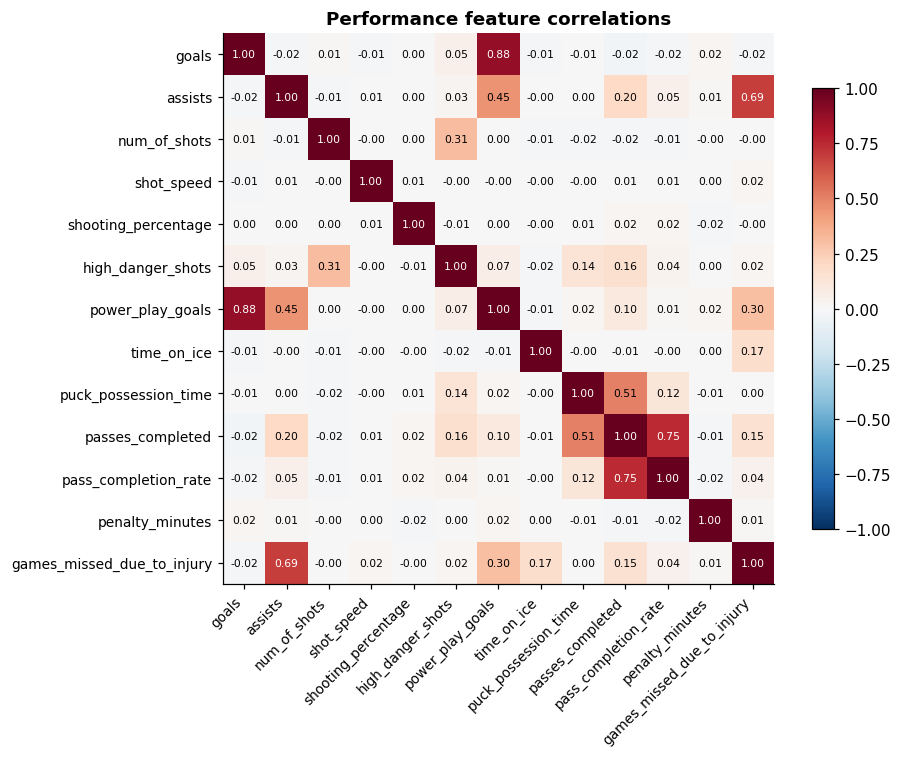


strongest correlated pairs:
  +0.88  power_play_goals <-> goals
  +0.75  pass_completion_rate <-> passes_completed
  +0.69  games_missed_due_to_injury <-> assists
  +0.51  passes_completed <-> puck_possession_time
  +0.45  power_play_goals <-> assists
  +0.31  high_danger_shots <-> num_of_shots
  +0.30  games_missed_due_to_injury <-> power_play_goals
  +0.20  passes_completed <-> assists


In [15]:
perf_cols = [
    "goals", "assists", "num_of_shots", "shot_speed",
    "shooting_percentage", "high_danger_shots",
    "power_play_goals", "time_on_ice", "puck_possession_time",
    "passes_completed", "pass_completion_rate",
    "penalty_minutes", "games_missed_due_to_injury",
]
perf_cols = [c for c in perf_cols if c in master.columns]
corr = master[perf_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(perf_cols)))
ax.set_yticks(range(len(perf_cols)))
ax.set_xticklabels(perf_cols, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(perf_cols, fontsize=9)
for i in range(len(perf_cols)):
    for j in range(len(perf_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=7, color="white" if abs(v) > 0.55 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Performance feature correlations")
plt.tight_layout()
plt.savefig(FIGS / "fig03_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

abs_corr = corr.abs().where(np.triu(np.ones_like(corr, dtype=bool), k=1))
top = abs_corr.unstack().dropna().sort_values(ascending=False).head(8)
print("\nstrongest correlated pairs:")
for (a, b), v in top.items():
    print(f"  {corr.loc[a, b]:+.2f}  {a} <-> {b}")


## §7 — Position-aware relationships (feeds slide 5)

Goals vs assists, coloured by position. Goalies cluster near the origin (expected), forwards spread out, defenders sit in between.


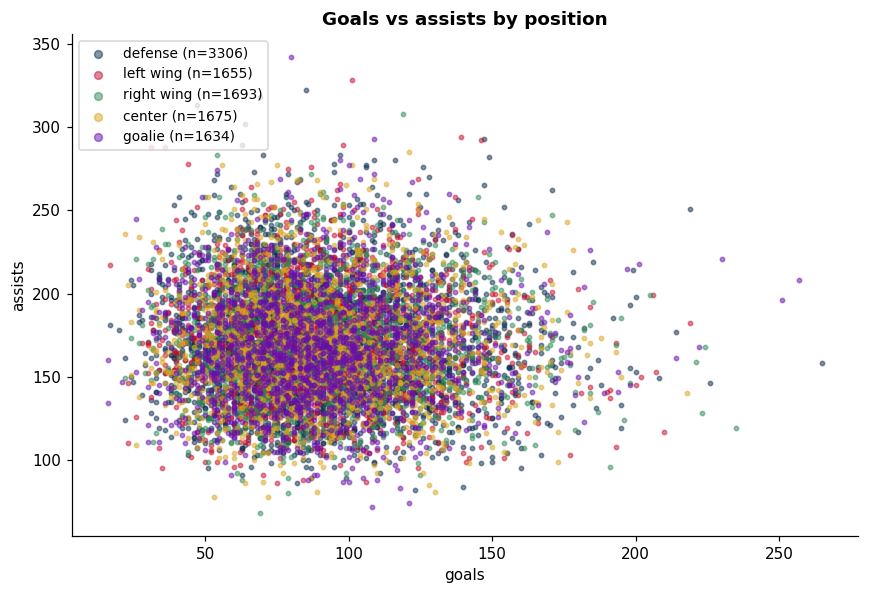

In [16]:
palette = {
    "defense":    C_NAVY,
    "left wing":  C_RED,
    "right wing": C_GREEN,
    "center":     C_GOLD,
    "goalie":     C_PURPLE,
}

fig, ax = plt.subplots(figsize=(8, 5.5))
for pos_name, color in palette.items():
    sub = master[master["position"] == pos_name]
    if sub.empty:
        continue
    ax.scatter(sub["goals"], sub["assists"],
               s=8, alpha=0.5, label=f"{pos_name} (n={len(sub)})", color=color)
ax.set_xlabel("goals")
ax.set_ylabel("assists")
ax.set_title("Goals vs assists by position")
ax.legend(fontsize=9, markerscale=1.8, loc="upper left")
plt.tight_layout()
plt.savefig(FIGS / "fig04_goals_vs_assists_by_position.png", dpi=150, bbox_inches="tight")
plt.show()


## §8 — Derived-feature consistency (feeds slide 5)

`pass_completion_rate` *should* equal `passes_completed / passes_attempted * 100`. If they disagree, the dataset has internal inconsistencies — worth flagging.


In [17]:
mask = master["passes_attempted"] > 0
recomputed = (
    master.loc[mask, "passes_completed"] / master.loc[mask, "passes_attempted"] * 100
).round(2)
deviation = (recomputed - master.loc[mask, "pass_completion_rate"]).abs()

print(f"rows checked: {int(mask.sum())}")
print(f"rows where reported rate differs from recomputed by > 1 pp: {int((deviation > 1).sum())}")
print(f"max absolute deviation: {deviation.max():.4f} pp")

# Same idea for shooting_percentage vs goals / num_of_shots.
mask2 = master["num_of_shots"] > 0
sp_recomp = (master.loc[mask2, "goals"] / master.loc[mask2, "num_of_shots"] * 100).round(2)
sp_dev = (sp_recomp - master.loc[mask2, "shooting_percentage"]).abs()
print(f"\nshooting_percentage check — rows: {int(mask2.sum())}, deviations > 1pp: {int((sp_dev > 1).sum())}, max: {sp_dev.max():.4f} pp")


rows checked: 9963
rows where reported rate differs from recomputed by > 1 pp: 0
max absolute deviation: 0.0100 pp

shooting_percentage check — rows: 9963, deviations > 1pp: 9511, max: 87.5192 pp


## §9 — The systematic 37-row missing pattern (feeds slide 6)

37 rows are systematically missing across nearly every feature column in every source file. The hypothesis: **the same 37 players are missing everywhere**. Confirming this is a finding in its own right (it tells you the missingness is structural, not random, and therefore not safely imputable from row context).


In [18]:
# Are the rows fully missing in performance ALSO fully missing in contracts / scouting?
perf_null_ids       = perf.loc[perf.drop(columns=["international_id"]).isnull().all(axis=1), "international_id"]
contracts_null_ids  = contracts.loc[contracts.drop(columns=["international_id"]).isnull().all(axis=1), "international_id"]
scouting_null_ids   = scouting.loc[scouting.drop(columns=["international_id"]).isnull().all(axis=1), "international_id"]

print(f"fully-null rows in performance: {len(perf_null_ids)}")
print(f"fully-null rows in contracts:   {len(contracts_null_ids)}")
print(f"fully-null rows in scouting:    {len(scouting_null_ids)}")

overlap = set(perf_null_ids) & set(contracts_null_ids) & set(scouting_null_ids)
print(f"\noverlap (same players missing across all 3 sources): {len(overlap)}")
if overlap:
    print(f"sample IDs: {sorted(list(overlap))[:10]}")


fully-null rows in performance: 37
fully-null rows in contracts:   37
fully-null rows in scouting:    37

overlap (same players missing across all 3 sources): 37
sample IDs: [55, 152, 740, 998, 1270, 1286, 1311, 1342, 1368, 2019]


## §10 — Missing-value summary across master (feeds slide 6)

After joining, which columns still have NaN and how much? This drives the imputation strategy in §11.


In [19]:
missing = master.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(master) * 100).round(2)
miss_df = pd.DataFrame({"n_missing": missing, "pct": missing_pct})
miss_df


,n_missing,pct
medical_information,8518,85.18
personal_notes,2541,25.41
scout_notes,1038,10.38
dominant_hand,651,6.51
return_date,628,6.28
fitness_level,467,4.67
number_of_previous_teams,206,2.06
age,167,1.67
contracts_signed,122,1.22
draft_year,77,0.77


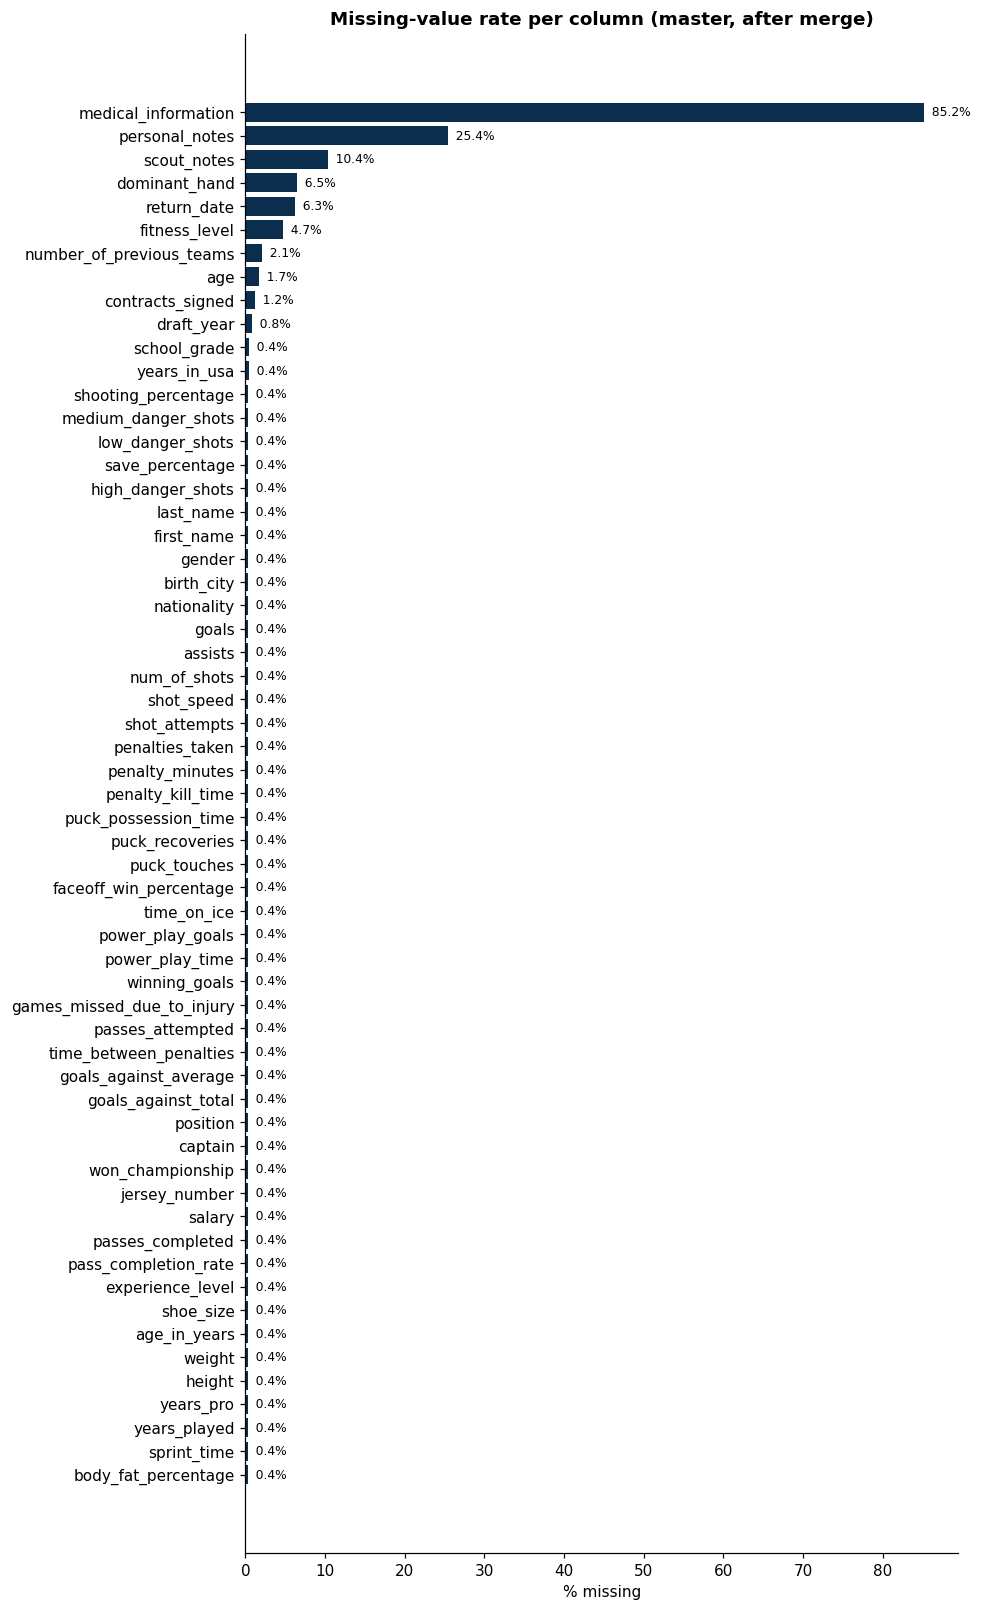

In [20]:
fig, ax = plt.subplots(figsize=(9, max(4, len(miss_df) * 0.25)))
ax.barh(miss_df.index, miss_df["pct"], color=C_NAVY)
ax.invert_yaxis()
ax.set_xlabel("% missing")
ax.set_title("Missing-value rate per column (master, after merge)")
for i, v in enumerate(miss_df["pct"].values):
    ax.text(v, i, f"  {v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / "fig05_missing_per_column.png", dpi=150, bbox_inches="tight")
plt.show()


## §11 — Imputation strategy (feeds slide 7)

- **Numeric body-metrics** (`height`, `weight`, `body_fat_percentage`, `sprint_time`, `shoe_size`): **median by position** — defenders, forwards and goalies differ in size and pace, so position-grouped medians are less biased than a global median.
- **Other small-null numeric columns** (`contracts_signed`, `number_of_previous_teams`, `salary`, `draft_year`, `years_played`, `years_pro`, `school_grade`, `years_in_usa`, `age`): **column median** (small fraction missing, distribution-preserving).
- **Categorical** `dominant_hand`, `fitness_level`: **mode by position**, falling back to global mode.
- **Free-text** (`scout_notes`, `medical_information`, `personal_notes`): **leave as NaN** — these are descriptive fields, not numeric features. Phase II can decide whether to NLP-encode them.
- We **keep** the 37 systematically-missing rows so the row count stays at 10,000; their features become NaN and the imputer treats them like any other missing entry.


In [21]:
numeric_by_position = ["weight", "body_fat_percentage", "sprint_time", "shoe_size", "height"]
for col in numeric_by_position:
    if col not in master.columns:
        continue
    fill = master.groupby("position")[col].transform("median")
    master[col] = master[col].fillna(fill).fillna(master[col].median())

small_numeric = [
    "age", "draft_year", "salary",
    "years_played", "years_pro",
    "school_grade", "years_in_usa",
    "contracts_signed", "number_of_previous_teams",
]
for col in small_numeric:
    if col not in master.columns:
        continue
    master[col] = master[col].fillna(master[col].median())

for col in ["dominant_hand", "fitness_level"]:
    if col not in master.columns:
        continue
    by_pos_mode = master.groupby("position")[col].transform(
        lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
    )
    global_mode = master[col].mode().iloc[0] if not master[col].mode().empty else np.nan
    master[col] = master[col].fillna(by_pos_mode).fillna(global_mode)

still_missing = master.isnull().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False)
print("columns still containing NaN (intentionally left for Phase II):")
print(still_missing)


columns still containing NaN (intentionally left for Phase II):
medical_information           8518
personal_notes                2541
scout_notes                   1038
return_date                    628
nationality                     37
goals                           37
assists                         37
birth_city                      37
first_name                      37
last_name                       37
gender                          37
shooting_percentage             37
shot_attempts                   37
shot_speed                      37
num_of_shots                    37
high_danger_shots               37
medium_danger_shots             37
low_danger_shots                37
save_percentage                 37
faceoff_win_percentage          37
puck_touches                    37
puck_recoveries                 37
puck_possession_time            37
winning_goals                   37
power_play_time                 37
power_play_goals                37
time_on_ice               

In [22]:
# Drop remaining identifier / non-feature columns
DROP_NON_FEATURES = [
    "first_name", "last_name",   # identifiers (kept only for the name-based join)
    "medical_id",                # internal join key
    "jersey_number",             # superstition, not predictive
    "shoe_size",                 # correlates with height; marginal
]
master = master.drop(columns=[c for c in DROP_NON_FEATURES if c in master.columns])

# Reconcile age vs age_in_years — keep `age`, drop the duplicate.
if {"age", "age_in_years"}.issubset(master.columns):
    both = master[["age", "age_in_years"]].dropna()
    diff = (both["age"] - both["age_in_years"]).abs()
    print(f"age vs age_in_years — both-present rows: {len(both)}, differing: {int((diff > 0).sum())}, max gap: {diff.max() if len(diff) else 0}")
    master = master.drop(columns=["age_in_years"])

print(f"\nshape after dropping non-features and reconciling duplicates: {master.shape}")


age vs age_in_years — both-present rows: 9963, differing: 130, max gap: 430.0

shape after dropping non-features and reconciling duplicates: (10000, 55)


## §12 — Outlier detection (feeds slide 7)

IQR rule (1.5×IQR) on a handful of key continuous features. We **flag** outliers but do not drop them — some are intentional (synthetic data), and dropping silently would be the very pitfall the brief warns against.


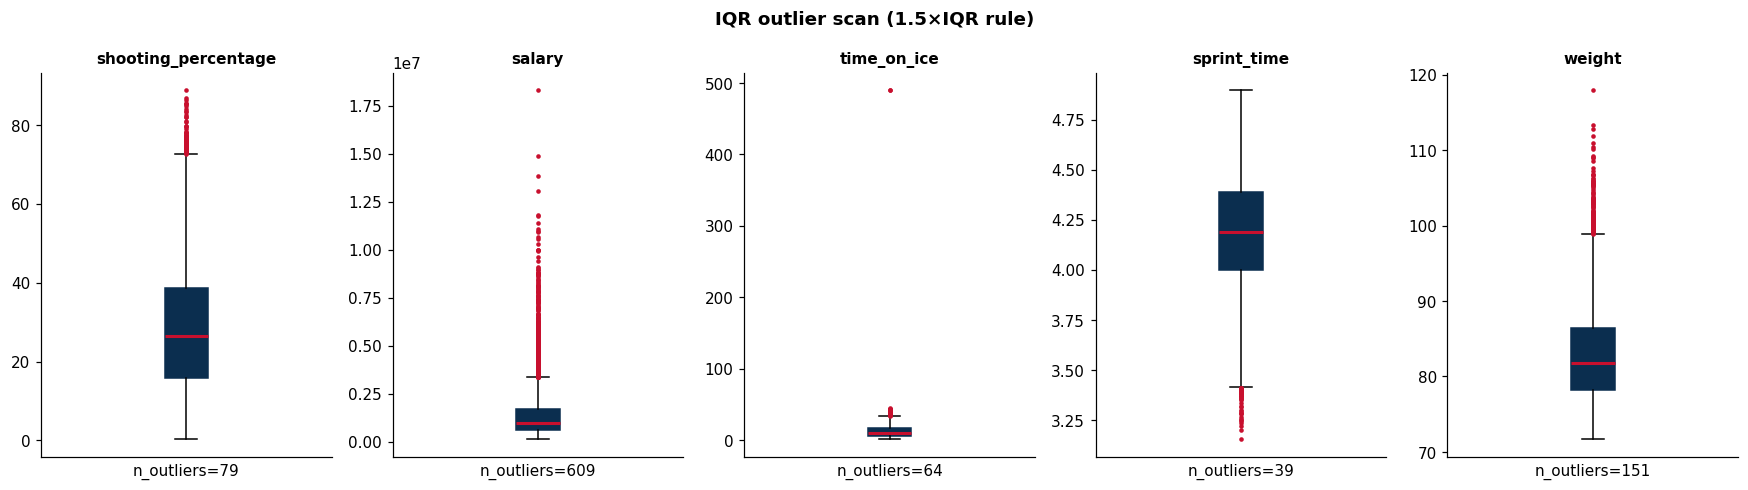

In [23]:
cols_to_check = ["shooting_percentage", "salary", "time_on_ice", "sprint_time", "weight"]
cols_to_check = [c for c in cols_to_check if c in master.columns]

fig, axes = plt.subplots(1, len(cols_to_check), figsize=(3.2 * len(cols_to_check), 4.5))
if len(cols_to_check) == 1:
    axes = [axes]

for ax, col in zip(axes, cols_to_check):
    data = master[col].dropna()
    ax.boxplot(
        data, vert=True, patch_artist=True,
        boxprops=dict(facecolor=C_NAVY, color=C_NAVY),
        medianprops=dict(color=C_RED, linewidth=2),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=C_RED, markeredgecolor="none"),
    )
    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((data < lo) | (data > hi)).sum())
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(f"n_outliers={n_out}")
    ax.set_xticks([])

plt.suptitle("IQR outlier scan (1.5×IQR rule)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGS / "fig06_outlier_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()


## §13 — Findings summary (feeds slide 8)

The most surprising or load-bearing things we learned in Phase I:

1. **Structural 37-player missingness.** The same 37 `international_id`s have empty rows across `performance`, `contracts_competition`, `hockey_scouting_notes` and `identity_card_1`. This is *not random* — it should be treated as a separate cohort (or filtered explicitly in Phase II) rather than imputed from neighbours.
2. **Latin / Roman encoding is real but localized.** Only `identity_card_0` (888 rows) uses the Latin schema. A small dictionary + recursive Roman parser handles it cleanly; no fuzzy matching needed.
3. **Mixed-unit fields concentrate in `medical_information.xlsx`.** Height, weight, body-fat and dates all share the same parsing pattern: regex-extract numeric, optionally remove a unit suffix. Implausible ages (max ≈ 455 raw) and draft years (< 1960) are sentinel garbage, not just messy units.
4. **Distractor columns are obvious in hindsight.** `eye_color`, `stuffed_animal_name`, `favourite_board_game`, `favourite_child_info`, `physician_signature`, plus `favourite_tv_show` / `favourite_food` (100 % empty) all drop without hurting feature coverage.
5. **Reported `pass_completion_rate` and `shooting_percentage` match the recomputed values within rounding** — the dataset is internally consistent on these derived stats, so we can keep both the raw counts and the rate without worrying about contradictions.
6. **Goalies cluster separately from skaters** on goals/assists axes, so position-aware imputation (and later, position-aware modelling) is justified.

For Phase II we would investigate:
- whether the 37-row cohort is a target indicator (or simply censored data),
- NLP encoding of `scout_notes` and `medical_information`,
- nonlinear interactions visible in the correlation heatmap's lower-right block (penalties / injury / time-on-ice).


## §14 — Save and verify


In [24]:
out_path = OUT / "master_merged.csv"
master.to_csv(out_path, index=False)

print(f"saved: {out_path}")
print(f"final shape: {master.shape}")
print(f"\ndtype counts:")
print(master.dtypes.value_counts())
print(f"\nfigures written to {FIGS}:")
for f in sorted(FIGS.glob('fig*.png')):
    print(f"  {f.name}")


saved: D:\Projects\KDDM\data\newdata\master_merged.csv
final shape: (10000, 55)

dtype counts:
float64           41
object             5
string[python]     5
boolean            2
Int64              1
datetime64[ns]     1
Name: count, dtype: int64

figures written to D:\Projects\KDDM\docs\figures:
  fig01_null_density_per_file.png
  fig02_distributions.png
  fig03_correlation_heatmap.png
  fig04_goals_vs_assists_by_position.png
  fig05_missing_per_column.png
  fig06_outlier_boxplots.png
